# Nashville Housing: графики и бизнес-выводы

Строим графики по очищенным данным о продажах жилья в Нашвилле (2013-2016) и сопровождаем каждый график выводом.


## 1. Подготовка

In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import os

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})
COLOR = "#2E6F95"
COLOR2 = "#E07A5F"
os.makedirs("charts", exist_ok=True)

def money(x, pos=None):
    return f"{x/1000:,.0f} тыс.".replace(",", " ")

## 2. Загрузка данных

In [ ]:

df = pd.read_csv('/content/nashvillehousing.csv')
print("Строк:", len(df), " Столбцов:", df.shape[1])

Строк: 56373  Столбцов: 25


Названия столбцов в выгрузке могут отличаться (`SalePrice`, `sale_price`, `"SalePrice"`). Приводим их к единому виду: нижний регистр, без пробелов и подчёркиваний.

In [ ]:
df.columns = [re.sub(r"[^a-z0-9]", "", c.lower()) for c in df.columns]

df["saledate"] = pd.to_datetime(df["saledate"])
df["year"] = df["saledate"].dt.year
df["month"] = df["saledate"].dt.month

print(df["year"].value_counts().sort_index())

year
2013    11292
2014    14274
2015    16734
2016    14071
2019        2
Name: count, dtype: int64


Данные охватывают 2013-2016 годы, в 2019 всего две строки. Поэтому дальше работаем с 2013-2016.

Для анализа жилья берём дома и жилые квартиры и отбрасываем явные выбросы: цены ниже 10 000 (символические сделки) и выше 5 млн (групповые сделки, см. раздел 7).

In [ ]:
period = df[df["year"].between(2013, 2016)]

housing = period[
    period["landuse"].isin(["SINGLE FAMILY", "RESIDENTIAL CONDO"])
    & (period["saleprice"] > 10_000)
    & (period["saleprice"] <= 5_000_000)
].copy()

print("Всего продаж 2013-2016:", len(period))
print("Жильё после фильтрации:", len(housing))

Всего продаж 2013-2016: 56371
Жильё после фильтрации: 47996


## 3. Динамика медианной цены по годам

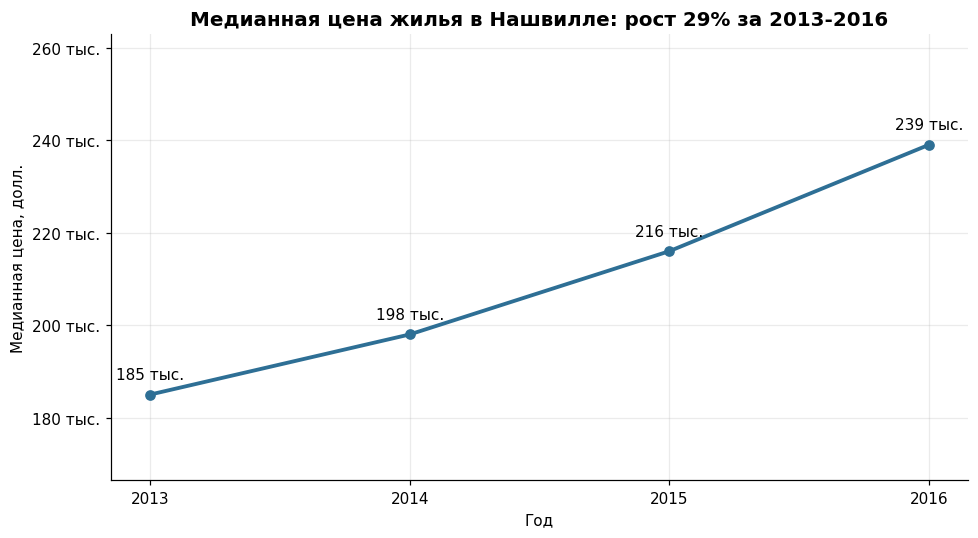

In [ ]:
by_year = housing.groupby("year")["saleprice"].median()
growth = (by_year.iloc[-1] / by_year.iloc[0] - 1) * 100

fig, ax = plt.subplots()
ax.plot(by_year.index, by_year.values, marker="o", color=COLOR, linewidth=2.5)
for x, y in by_year.items():
    ax.annotate(money(y), (x, y), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_xticks(by_year.index)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_ylim(by_year.min() * 0.9, by_year.max() * 1.1)
ax.set_title(f"Медианная цена жилья в Нашвилле: рост {growth:.0f}% за 2013-2016")
ax.set_xlabel("Год")
ax.set_ylabel("Медианная цена, долл.")
plt.tight_layout()
plt.savefig("charts/01_median_by_year.png")
plt.show()

**Вывод.** Рынок рос из года в год, суммарно примерно на 29%. Для покупателя это означает, что каждый год ожидания дешевле обходился дороже, для инвестора, что рынок был устойчиво растущим.

## 4. Рост цен по городам

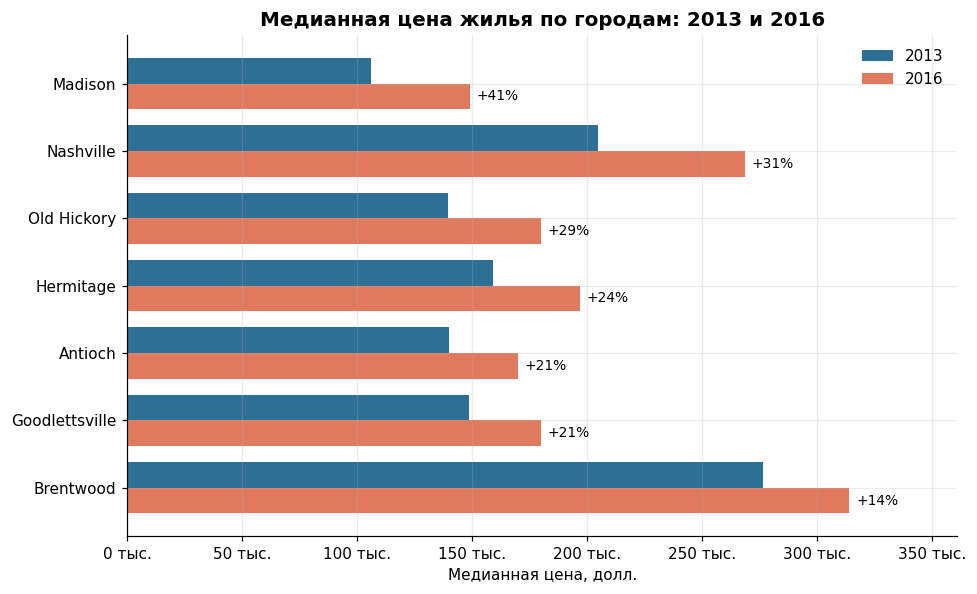

In [ ]:
med = housing.groupby(["propertycity", "year"])["saleprice"].median().unstack()
cnt = housing.groupby("propertycity").size()

big = cnt[cnt > 500].index
city = med.loc[med.index.intersection(big), [2013, 2016]].dropna()
city["growth"] = (city[2016] / city[2013] - 1) * 100
city = city.sort_values("growth")

fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(city))
h = 0.38
ax.barh(y + h/2, city[2013], height=h, color=COLOR, label="2013")
ax.barh(y - h/2, city[2016], height=h, color=COLOR2, label="2016")
ax.set_yticks(y)
ax.set_yticklabels(city.index.str.title())
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
for i, (_, r) in enumerate(city.iterrows()):
    ax.text(r[2016] + 3000, i - h/2, f"+{r['growth']:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, city[2016].max() * 1.15)
ax.set_title("Медианная цена жилья по городам: 2013 и 2016")
ax.set_xlabel("Медианная цена, долл.")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("charts/02_growth_by_city.png")
plt.show()

**Вывод.** Быстрее всего росли более доступные районы (Madison, Old Hickory, Hermitage), а самый дорогой Brentwood вырос слабее остальных. Спрос смещался в доступные пригороды, поэтому для застройщиков они были самыми перспективными.

## 5. Сезонность продаж

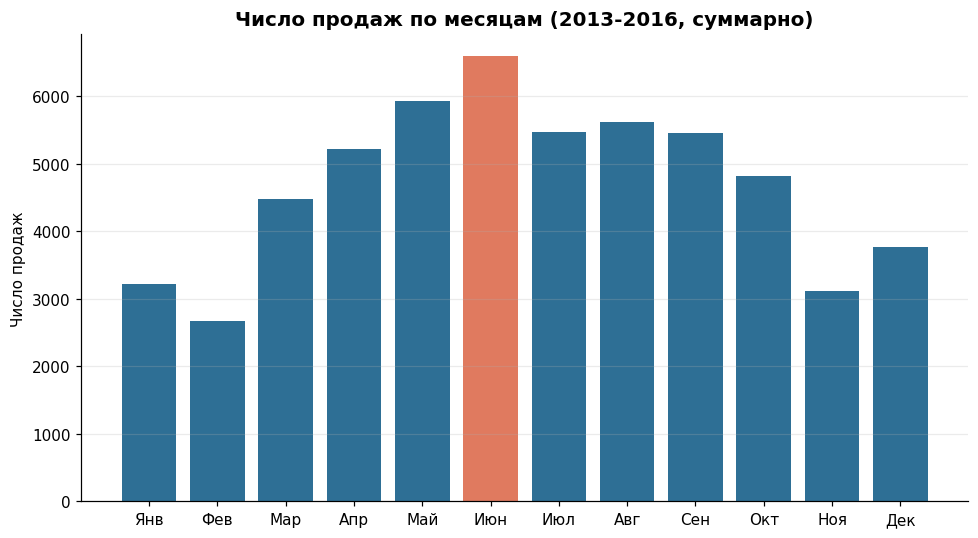

In [ ]:
months = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
season = period.groupby("month").size().reindex(range(1, 13))

fig, ax = plt.subplots()
colors = [COLOR2 if v == season.max() else COLOR for v in season.values]
ax.bar(months, season.values, color=colors)
ax.set_title("Число продаж по месяцам (2013-2016, суммарно)")
ax.set_ylabel("Число продаж")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("charts/03_seasonality.png")
plt.show()

**Вывод.** Пик продаж приходится на май-август, минимум на январь-февраль и ноябрь. Рекламные бюджеты и сезонный найм агентствам имеет смысл смещать на весну и лето.

## 6. Цена и число спален (частные дома)

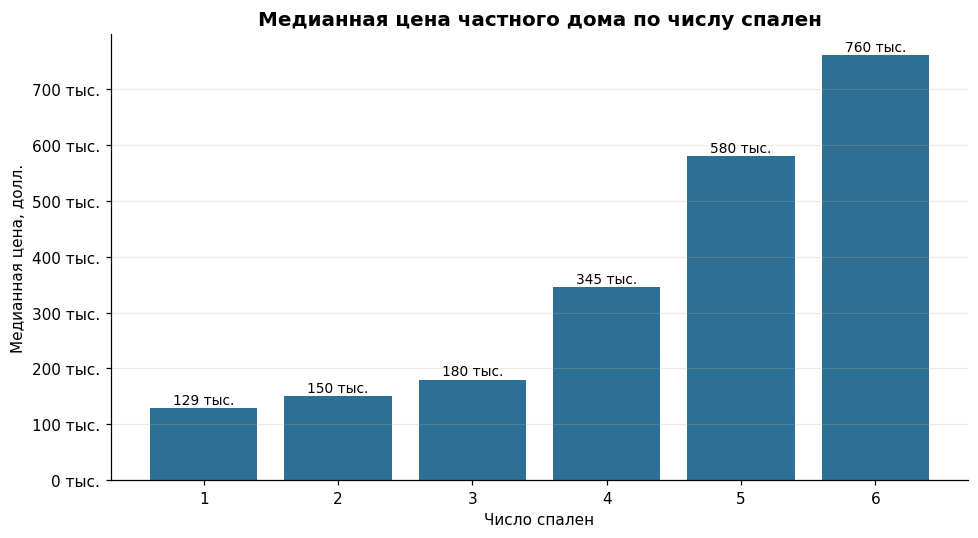

In [ ]:
sf = housing[(housing["landuse"] == "SINGLE FAMILY") & housing["bedrooms"].between(1, 6)]
beds = sf.groupby("bedrooms")["saleprice"].median()

fig, ax = plt.subplots()
ax.bar(beds.index.astype(int).astype(str), beds.values, color=COLOR)
for i, v in enumerate(beds.values):
    ax.text(i, v + 8000, money(v), ha="center", fontsize=9)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_title("Медианная цена частного дома по числу спален")
ax.set_xlabel("Число спален")
ax.set_ylabel("Медианная цена, долл.")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("charts/04_price_by_bedrooms.png")
plt.show()

**Вывод.** Цена растёт нелинейно: переход с 3 на 4 спальни почти удваивает медиану. Для застройщика это аргумент в пользу проектов на 4 и более спальни там, где позволяют участки.

## 7. Почему мы считаем медиану, а не среднее

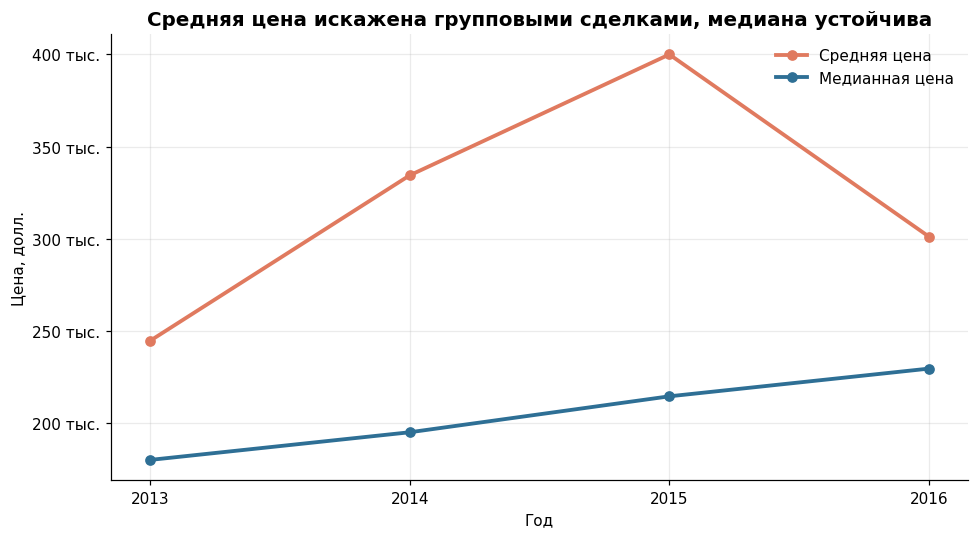

,legalreference,saledate,saleprice,units
6,20150202-0009517,2015-01-30,13156000,92
4,20140829-0079368,2014-08-26,5491000,30
7,20150716-0069771,2015-07-14,14100000,23
5,20141217-0115478,2014-12-17,54278060,7
2,20140811-0072057,2014-08-08,9500000,6


In [ ]:
all_by_year = period.groupby("year")["saleprice"].agg(["mean", "median"])

fig, ax = plt.subplots()
ax.plot(all_by_year.index, all_by_year["mean"], marker="o", color=COLOR2, linewidth=2.5, label="Средняя цена")
ax.plot(all_by_year.index, all_by_year["median"], marker="o", color=COLOR, linewidth=2.5, label="Медианная цена")
ax.set_xticks(all_by_year.index)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_title("Средняя цена искажена групповыми сделками, медиана устойчива")
ax.set_xlabel("Год")
ax.set_ylabel("Цена, долл.")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("charts/05_mean_vs_median.png")
plt.show()

big_deals = (
    period[period["saleprice"] > 5_000_000]
    .groupby(["legalreference", "saledate", "saleprice"]).size()
    .reset_index(name="units")
    .sort_values("units", ascending=False)
    .head(5)
)
big_deals

**Вывод.** Из 163 продаж дороже 5 млн долларов 160 это групповые сделки, где цена всей сделки записана на каждый объект (например, 92 квартиры с ценой 13,2 млн за каждую). Из-за них средняя цена в 2015 году взлетает, а в 2016 падает, хотя медиана растёт. Поэтому во всех выводах используется медиана с фильтрацией выбросов.

## 8. Цена продажи и налоговая оценка (частные дома)

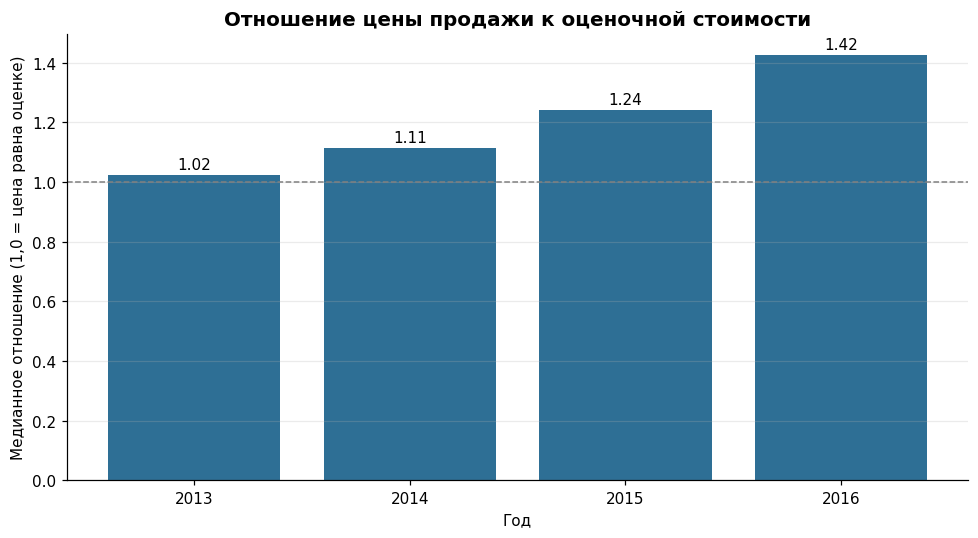

In [ ]:
sf2 = period[
    (period["landuse"] == "SINGLE FAMILY")
    & (period["totalvalue"] > 0)
    & (period["saleprice"] > 10_000)
].copy()
sf2["ratio"] = sf2["saleprice"] / sf2["totalvalue"]
ratio = sf2.groupby("year")["ratio"].median()

fig, ax = plt.subplots()
ax.bar(ratio.index.astype(str), ratio.values, color=COLOR)
for i, v in enumerate(ratio.values):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_title("Отношение цены продажи к оценочной стоимости")
ax.set_xlabel("Год")
ax.set_ylabel("Медианное отношение (1,0 = цена равна оценке)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("charts/06_price_to_assessed.png")
plt.show()

**Вывод.** Отношение цены продажи к оценке выросло с 1,02 в 2013 до 1,42 в 2016: рыночные цены обгоняли налоговую оценку. Для налоговых органов это сигнал о занижении базы, для инвесторов о перегреве рынка относительно официальных оценок.

## 9. Ограничения

- Данные охватывают 2013-2016 годы и один округ.
- Города определены по почтовым адресам, а не по микрорайонам.
- Мы видим, что цены росли, но не знаем причин (процентные ставки, миграция, новое строительство)